# Assignment 3 - [student name]_[student ID]

It is your turn to design the structure of the work.


# Preprocessing

=> Class mapping (name -> id):
0: basophil
1: eosinophil
2: erythroblast
3: ig
4: lymphocyte
5: monocyte
6: neutrophil
7: platelet

=> The first few rows of the training DataFrame:
                       filepath class_name  class_id
0  train/basophil/BA_689200.jpg   basophil         0
1  train/basophil/BA_347981.jpg   basophil         0
2  train/basophil/BA_391096.jpg   basophil         0
3  train/basophil/BA_152930.jpg   basophil         0
4  train/basophil/BA_991876.jpg   basophil         0
=> Number of training images found: 3200

=> Image size distribution in training set (width, height → count):
(360, 363) : 3120
(366, 369) : 49
(360, 360) : 30
(359, 360) : 1

=> Number of corrupted and unreadable images: 0
=> Final number of training images after cleaning: 3200


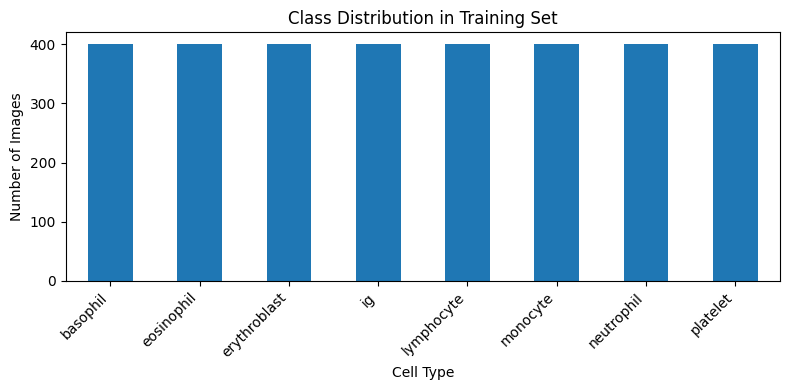


=> Class counts:
class_name
basophil        400
eosinophil      400
erythroblast    400
ig              400
lymphocyte      400
monocyte        400
neutrophil      400
platelet        400
Name: count, dtype: int64

=> Split sizes:
Training split : 2560
Validation split: 640

=> Computed channel statistics (training-only) for normalisation:
Mean: tensor([0.8738, 0.7489, 0.7215])
Standard deviation : tensor([0.1599, 0.1854, 0.0800])

=> DataLoaders are ready:
Number of training batches   : 80
Number of validation batches : 20
Number of test batches       : 32


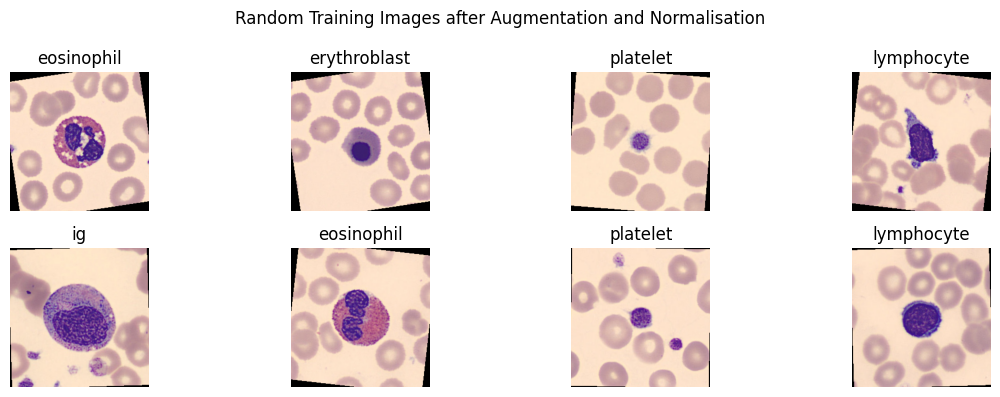

In [1]:
# Firstly, we will perform preprocessing for blood cell image classification.
# In this section, I use the knowledge learned to implement this part including from workshop 1 titled: "Python Basics with Jupyter Notebook", workshop 2 titled: "Tensor Basics", workshop 3 titled: "Autograd: Automatic Differentiation", workshop 4 titled: "Training a Classifier" and workshop 7 and 8 titled: "Attention Is All You Need".
# Step 1: We will import the library needed for this section, which will help readers understand more easily the beginning of our code in this section.
import os
import json
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
# In my computer, to be more detailed if we run this command in Jupyter, this magic will show the graphs inside the notebook, and in the .py script you can comment out this line.
%matplotlib inline
# Step 2: we proceed to define the path and load the class map.
# We use the root directory containing the train/, test/ and JSON files, then we proceed to use Path instead of raw strings which makes the code more portable across operating systems.
DATA_DIR = Path(".")
# Then, we proceed to create the path to the image folder.
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR  = DATA_DIR / "test"
# Then, we proceed to create the JSON path that defines the class_name -> class_id mapping.
CLASS_MAP_PATH = DATA_DIR / "class_map.json"
# Then, we continue to load the mapping from JSON so we can then convert the folder names to numeric labels.
with open(CLASS_MAP_PATH, "r") as f:
    class_map = json.load(f)
# Then, this is one of the important steps, we do the reverse mapping: class_id -> class_name, through which we see that it is very useful for the charts and titles later when doing the next steps.
id_to_class = {cid: cname for cname, cid in class_map.items()}
print("=> Class mapping (name -> id):")
for cname, cid in class_map.items():
    print(f"{cid}: {cname}")
# Step 3: we proceed to scan the documents and folders that the question has instructed and then we will build the data frame of our part.
# Then, for a detailed illustration, we will demonstrate by building a DataFrame with columns, details as follows:
# + filepath: we will note about the full path to the image file
# + class_name: we will mention the string label that the question is asking for (e.g, "basophil").
# Through this, we see that having a structured table makes it much easier to separate statistics and debug.
filepaths   = []
class_names = []
class_ids   = []
# Then, we proceed to iterate over each class in the class_map and scan the corresponding directory.
for cname, cid in class_map.items():
    class_folder = TRAIN_DIR / cname
    if not class_folder.exists():
# At this point, we see that this usually doesn't happen; we'll print a warning if the directory is missing. And that makes it easier to check when debugging and reviewing code, saving us time when we're done.
        print(f"WARNING: Class folder does not exist: {class_folder}")
        continue
# Then, we proceed to iterate over all the files in this directory.
    for fname in os.listdir(class_folder):
        # Only keep image files (jpg / jpeg / png).
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            fpath = class_folder / fname
            filepaths.append(str(fpath))
            class_names.append(cname)
            class_ids.append(cid)
# Finally, we will proceed to create a DataFrame summarizing the training dataset.
train_df = pd.DataFrame({
    "filepath":   filepaths,
    "class_name": class_names,
    "class_id":   class_ids,
})
print("\n=> The first few rows of the training DataFrame:")
print(train_df.head())
print("=> Number of training images found:", len(train_df))
# Step 4: We proceed to the most important step which is to perform basic data cleaning through which we check for corrupted images and appropriate image sizes.
# Then we will do the following by trying to open every image using PIL, next we will record the image size (width, height), finally we will collect any images that cannot be opened or are corrupted. This ensures our dataset is clean and avoids runtime errors during model training.
bad_files = []                  # We create a place to store file paths that cannot be opened.
image_size_counter = Counter()  # We create a place to count different image sizes.
for fp in train_df["filepath"]:
    try:
        with Image.open(fp) as img:
# Then we convert to RGB to have 3 unified channels for all images.
            img = img.convert("RGB")
            image_size_counter[img.size] += 1  # img.size is (width, height)
    except Exception as e:
        print(f"Error reading image: {fp} | {e}")
        bad_files.append(fp)
print("\n=> Image size distribution in training set (width, height → count):")
# We observe that knowing the image size distribution helps decide whether global resizing is needed, which is important to have better control over how clean our data is.
for size, count in image_size_counter.items():
    print(size, ":", count)
print("\n=> Number of corrupted and unreadable images:", len(bad_files))
# We proceed to remove corrupted images from the DataFrame if any.
if bad_files:
    train_df = train_df[~train_df["filepath"].isin(bad_files)].reset_index(drop=True)
print("=> Final number of training images after cleaning:", len(train_df))
# Step 5: We perform visualization to clarify our data, through which we will perform visualization using class distribution, more specifically a bar chart.
# We do a count of how many images we have for each class_name.
class_counts = train_df["class_name"].value_counts().sort_index()
plt.figure(figsize=(8, 4))
class_counts.plot(kind="bar")
plt.title("Class Distribution in Training Set")
plt.xlabel("Cell Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print("\n=> Class counts:")
print(class_counts)
# Step 6: We proceed to separate labeled data into training and validation (they are clearly stratified).
# In this step, we see that it is very important, because the separation of the training and validation sets must be done before any normalization and statistical processes in the preprocessing of this data.
# And through that we see that this is to avoid data leakage. The validation data must not affect the mean and standard estimates.
train_df_split, val_df_split = train_test_split(
    train_df,
    test_size=0.2,                # We see that 20% of the data is used for validation.
    random_state=42,              # We conduct fixed seed for reproducibility.
    stratify=train_df["class_id"] # We proceed to keep the class distribution balanced in both sections.
)
print("\n=> Split sizes:")
print("Training split :", len(train_df_split))
print("Validation split:", len(val_df_split))
# Step 7: we calculate the average and channel series only on the training split, and in the data the images are resized to fixed size.
# Then, we see that we are only calculating the normalized statistics, more specifically the mean and standard, on the training split. This simulates a real-world scenario where the model never sees validation and test data.
IMG_SIZE = (256, 256)  # It is the common resolution for all images (height, width).
stats_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),  # ensure all images have the same size
    transforms.ToTensor()         # convert to tensor with values in [0, 1]
])
# Then, we see that the dataset is only used to calculate statistics, more specifically the mean and standard deviation. It then returns a tensor image after applying stats_transform.
class StatsDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        fp = self.df.iloc[idx]["filepath"]
        img = Image.open(fp).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img
# Then, we proceed to build the dataset and DataLoader to calculate statistics based only on the train split above.
stats_dataset = StatsDataset(train_df_split, transform=stats_transform)
stats_loader = DataLoader(stats_dataset, batch_size=32, shuffle=False)
# Then, we proceed to create the accumulator for the statistics.
n_pixels = 0
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
for batch in stats_loader:
 # Then, we analyze further that the lot has shape (B, C, H, W).
    b, c, h, w = batch.shape
    n_pixels += b * h * w
# Then we proceed to calculate the batch and spatial sums for each channel. Then we proceed to use the sum and sum of squares which allows us to calculate the exact mean and variance.
    channel_sum += batch.sum(dim=[0, 2, 3])
    channel_sum_sq += (batch ** 2).sum(dim=[0, 2, 3])
# Then, we calculate the mean and standard values ​​for each channel.
mean = channel_sum / n_pixels
std = torch.sqrt(channel_sum_sq / n_pixels - mean ** 2)
print("\n=> Computed channel statistics (training-only) for normalisation:")
print("Mean:", mean)
print("Standard deviation :", std)
# Step 8: We proceed to define transformations for training, validation and testing.
# Then, we see that about the training transformation. Next, we perform Resize to the same IMG_SIZE used for statistics. Next, we will proceed with random flipping and small rotation to augment the data. Then, we see that the augmentation has contributed to improve the generalization ability by introducing small variations. In this section, we continue with the transformation to tensor, which is also an important step. Finally, we perform normalization using the calculated mean and standard deviation.
train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])
# Then we proceed to perform validation and transformation checking. We do this by not needing random augmentation, only deterministic operations. We see that this ensures that the evaluation is consistent and not affected by randomness.
val_test_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])
# Step 9: We continue to define the data set and the data load object.
# Then, we observe that the common dataset for training and validation, consists of:
# Each __getitem__ returns:
# - image tensor (C, H, W), after transformation
# - class_id integer
# Thereby, we see that wrapping the DataFrame in a Dataset allows us to use PyTorch's DataLoader to automatically create shuffled mini-batches for training in the most efficient way.
class BloodCellDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        label = row["class_id"]
        return img, label
# We proceed to build the training and validation dataset.
train_dataset = BloodCellDataset(train_df_split, transform=train_transform)
val_dataset   = BloodCellDataset(val_df_split,   transform=val_test_transform)
# We proceed to build DataLoaders (mini-batch).
BATCH_SIZE = 32
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,      # We see that it is important to shuffle during training to optimize randomization better.
    num_workers=0      # To make the code run safely on my computer and yours, we use set to 0 if you have problems on Windows.
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)
# We sense that the test dataset consists of unlabeled images. From there, we store the file path for linking. Next, we continue with the predictions back to the following file name.
test_filepaths = sorted([
    str(TEST_DIR / fname)
    for fname in os.listdir(TEST_DIR)
    if fname.lower().endswith((".jpg", ".jpeg", ".png"))
])
# Then, we execute the test set dataset against unlabeled.
# Then, we see that each __getitem__ returns:
# - image tensor (C, H, W)
# - file path string (which we see is useful for writing prediction_labels.json later)
# Then, we see that keeping the filename intact so that we can write the prediction in the correct format required by the assignment (mapping filename → predicted label) is important at this step.
class TestDataset(Dataset):
    def __init__(self, filepaths, transform=None):
        self.filepaths = filepaths
        self.transform = transform
    def __len__(self):
        return len(self.filepaths)
    def __getitem__(self, idx):
        fp = self.filepaths[idx]
        img = Image.open(fp).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, fp
test_dataset = TestDataset(test_filepaths, transform=val_test_transform)
test_loader  = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)
print("\n=> DataLoaders are ready:")
print(f"Number of training batches   : {len(train_loader)}")
print(f"Number of validation batches : {len(val_loader)}")
print(f"Number of test batches       : {len(test_loader)}")
# Step 10: we visualize some training images after augmentation.
# Then, we visualize some random training samples after applying augmentation and normalization. Next, we denormalize the tensors before plotting to make the visualization look natural, and finally, we visualize the augmented samples to verify the process and provide intuition about the learning task.
def show_training_examples(dataset, n_images=8):
# Then, we continue with randomly selecting n_images index from the dataset.
    indices = np.random.choice(len(dataset), size=n_images, replace=False)
    plt.figure(figsize=(12, 4))
    for i, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
# Then, we have the formula related to denormalization: x * std + Mean.
        denorm = img_tensor * std[:, None, None] + mean[:, None, None]
        denorm = denorm.clamp(0, 1)  # We make sure the values ​​are in [0, 1]
# They perform the transformation of tensor (C, H, W) -> numpy image (H, W, C).
        img_np = denorm.permute(1, 2, 0).numpy()
        plt.subplot(2, n_images // 2, i + 1)
        plt.imshow(img_np)
        plt.axis("off")
        plt.title(id_to_class[int(label)])
    plt.suptitle("Random Training Images after Augmentation and Normalisation")
    plt.tight_layout()
    plt.show()
# Finally, we make this call once to visually check the preprocessing pipeline.
show_training_examples(train_dataset, n_images=8)

# Model Implementation

In [2]:
# We will continue with the next part, which is Model Implementation.
# In this section, I use the knowledge learned to implement this part including from workshop 1 titled: "Python Basics with Jupyter Notebook", workshop 2 titled: "Tensor Basics", workshop 3 titled: "Autograd: Automatic Differentiation", workshop 4 titled: "Training a Classifier", workshop 5 titled: "NLP_RNN", workshop 6 titled: "TorchVision Object Detection Finetuning Tutorial" and workshop 7 and 8 titled: "Attention Is All You Need".
# First of all, we will create the python libraries needed for this section.
import torch
import torch.nn as nn
import torch.nn.functional as F
NUM_CLASSES = 8
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Step 1: We proceed with base model 1 which is linear classifier.
# Firstly, we continue with creating Baseline 1: A simple linear classifier that flattens the entire image into a 1D vector and feeds it into a single fully connected layer.
# Then we see that this model does not learn spatial, texture or edge patterns, making it extremely weak but useful as a benchmark with minimal performance loss compared to CNN.
# Then, we observe how poorly the models perform without convolutional feature extraction, and thus justify the use of deep learning models later.
class BaselineLinear(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, input_size=(3, 256, 256)):
        super().__init__()
        c, h, w = input_size
        in_features = c * h * w  # We observe that the total number of pixels in the entire image.
# We observe that the single linear layer maps the planar pixels resulting in layer points.
        self.fc = nn.Linear(in_features, num_classes)
    def forward(self, x):
# Then we see that flattens the image while keeping the batch size the same.
        x = x.view(x.size(0), -1)
        return self.fc(x)
# Step 2: We proceed to create the base model 2 which is the small CNN.
# Firstly, we implement Baseline 2: A shallow CNN with two convolutional blocks. We see that each block extracts increasingly complex features (e.g., edge → texture → shape). Although much weaker than our main model, it uses CNN principles and thus provides a stronger baseline than the linear model.
# Then, we observe that this model helps illustrate how deeper architectures outperform shallow architectures, especially from an individual perspective, in more complex bioimaging tasks such as blood cell recognition.
class BaselineSmallCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
# We will create Block 1: We will implement BatchNorm's basic low-level image feature extraction like edges, gradients, and textures. And then we see from there that it helps stabilize the activations and MaxPool decreases, thereby increasing the spatial resolution, increasing efficiency.
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
# We will create Block 2: We will implement learning of slightly more complex patterns, such as local shapes or contours. We see that increasing the number of channels deepens, and thus the feature representation, allowing the network to build, and more specifically, a deeper understanding of the image structure.
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
# Then, we perform global pooling converting each feature map into one, while we find that the single representative value, removes spatial sensitivity while preserving the most important information at the channel level.
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
# Then, we feel that the final fully connected classifier maps the pooled features, which in turn form the class logit.
        self.classifier = nn.Linear(32, num_classes)
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)
# Step 3: We proceed to create ConvBlock, which is also the reusable block for the main model.
# Firstly, we see that ConvBlock: A reusable building block consisting of Conv → BatchNorm → ReLU. We observe that encapsulating these operations into a single class improves modularity and simplifies building deeper architectures. From this, we see that this block helps maintain a consistent structure, minimizes code repetition, and makes the main CNN architecture easier to read and maintain.
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.bn   = nn.BatchNorm2d(out_channels)
        self.act  = nn.ReLU(inplace=True)
    def forward(self, x):
# Then we apply convolution, normalization, and then activation to create non-linearity.
        return self.act(self.bn(self.conv(x)))
# Step 4: We proceed to create the proposed main model, which is the Deep CNN model built from scratch.
class BloodCellCNN(nn.Module):
# Firstly, we will form the main model, we observe that a deeper convolutional neural network is designed to learn hierarchical features from blood cell images. The earlier layers learn simple textures, while the deeper layers capture complex cell morphology (nucleus shape, granules, boundaries).
# Then, we see that this model is implemented completely from scratch using PyTorch OOP and forms the core of our dataset classification system.
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
# Then, we proceed to create Block 1: That is the low-level feature extraction, we proceed to record edges, gradients, simple blobs and other primitive patterns.
# Then, we observe that the initial CNN layers focus on fine-grained local structures that appear in all types of cells. And also MaxPooling reduces the resolution to control the cost.       
        self.block1 = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 32),
            nn.MaxPool2d(2),
            nn.Dropout(0.10)
        )
# Then we move on to build Block 2: That is, mid-level feature extraction. We move on to learning more abstract patterns like cell contours, cytoplasmic textures, and broader structural shapes.
# Then, we see that the additional channels allow the model to encode richer information and better discriminate.
        self.block2 = nn.Sequential(
            ConvBlock(32, 64),
            ConvBlock(64, 64),
            nn.MaxPool2d(2),
            nn.Dropout(0.15)
        )
# Then, we proceed to create Block 3: That is the semantic feature level. We see that the detection of complex biological structures such as cell nuclei and their variations, grain density and class-specific features.
# Then, we observe that at this depth, the model learns abstract feature maps that are closely correlated with cell groups.
        self.block3 = nn.Sequential(
            ConvBlock(64, 128),
            ConvBlock(128, 128),
            nn.MaxPool2d(2),
            nn.Dropout(0.20)
        )
# Then, we observe that global average pooling aggregates the spatial information across each feature map, reducing it to a single value. We observe that this makes the model more robust to small displacements.
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
# Step 5: We see that the classifier head (MLP), in this step we perform the conversion of high-level CNN features into final predictions. Besides, dropout reduces overfitting by preventing co-adaptation.
        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
# Then, we perform forward pass through deeper feature extraction layers.
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
# Then, we implement the spatial dimensions of the pool into a compact vector.
        x = self.gap(x)
        x = x.view(x.size(0), -1)
# Finally, we perform a final classification into cell types.
        return self.classifier(x)
# Step 6: We come to the model factory, which is also an option for clean model.
def create_model(name: str):
# In this step we see that factory function, we see that the most important thing is that it allows switching between base model and main model using a single name. This helps to keep the training script clean, readable and easy to modify.
    name = name.lower()
    if name in ["linear", "baseline_linear"]:
        return BaselineLinear()
    elif name in ["small_cnn", "baseline_smallcnn"]:
        return BaselineSmallCNN()
    elif name in ["main_cnn", "bloodcellcnn"]:
        return BloodCellCNN()
    else:
        raise ValueError(f"Unknown model: {name}")
# Step 7: We proceed to execute the optional sanity test.
if __name__ == "__main__":
    x = torch.randn(4, 3, 256, 256).to(device)
    for name in ["linear", "small_cnn", "main_cnn"]:
        model = create_model(name).to(device)
        out = model(x)
        print(f"{name} output shape: {out.shape}")

linear output shape: torch.Size([4, 8])
small_cnn output shape: torch.Size([4, 8])
main_cnn output shape: torch.Size([4, 8])


# Experiments

In [3]:
#  We continue with the next part which is Experiments.
# In this section, I use the knowledge learned to implement this part including from workshop 1 titled: "Python Basics with Jupyter Notebook", workshop 2 titled: "Tensor Basics", workshop 3 titled: "Autograd: Automatic Differentiation", workshop 4 titled: "Training a Classifier", workshop 5 titled: "NLP_RNN", workshop 6 titled: "TorchVision Object Detection Finetuning Tutorial" and workshop 7 and 8 titled: "Attention Is All You Need".
# Firstly, we will create the python libraries required for this section.
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score
# Step 1: We proceed with the configuration that is we will list out which experiments are in this section and the hyperparameters in this section.
# First of all, we observe that flags to control the experiments are performed. In addition, we see that these flags must match the experiments described in the report.
RUN_BASELINE1 = True     # Linear baseline
RUN_BASELINE2 = True     # Small CNN baseline
RUN_MAIN      = True     # Main proposed CNN (Blood Cell CNN)
RUN_ABLATION  = True     # Ablation: main CNN without dropout
# Then we observe that we will create the number of epochs used for each model type. We feel that if we change these epochs, we will be updating the report so that the reported results are consistent.
EPOCHS_BASELINE1 = 40
EPOCHS_BASELINE2 = 40
EPOCHS_MAIN      = 30
EPOCHS_ABLATION  = 30
# Then, we will continue with creating learning rate for each experiment. Through this, we see that currently, we use the same learning rate for all the models, but keep them separate to give more flexibility to our model.
LR_BASELINE1 = 1e-3
LR_BASELINE2 = 1e-3
LR_MAIN      = 1e-3
LR_ABLATION  = 1e-3
# Then, we will continue with the global regularization and early stopping settings shared by all experiments.
WEIGHT_DECAY = 1e-4      # We observe that small L2 regularization aids generalization.
PATIENCE     = 26         # We see that patience stops early, which is also the period of no real improvement.
# Step 2: We come to create a one-epoch training loop.
def train_one_epoch(model, loader, criterion, optimizer, device):
# To begin with, we proceed with training the model in a single epoch and return the average loss and accuracy. We see that this function consists of: that is, we will perform the model to train mode, then we perform the training loader iteration, next we perform the forward and backward passes and update the optimizer. Finally, we perform the collection of predictions and labels to calculate the accuracy at the end of the model.
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
# Next, we see that next we will move the data to the selected device (CPU/GPU).
        imgs, labels = imgs.to(device), labels.to(device)
# Then, we observe that the steps are as follows: zero grad -> forward -> loss -> backward -> step.
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
# Next, we proceed to perform loss accumulation to calculate the average.
        total_loss += loss.item()
# Then, we proceed with storing the predictions and labels to calculate the accuracy.
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
# Finally, we continue with calculating the training accuracy over the entire epoch.
    acc = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), acc
# Step 3: We come to the validation loop.
def evaluate(model, loader, criterion, device):
# Firstly, we will evaluate the model on the validation set and return the accuracy and loss. We will analyze this function in depth by how we switch the model to evaluation mode like disabling dropout etc. Next, we disable gradient computation for efficiency. Finally, we perform loss and average accuracy computation on the validation loader.
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)
            loss = criterion(logits, labels)
            total_loss += loss.item()
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
    acc = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), acc
# Step 4: We will proceed with the generic experiment runner and have the best model tracking.
def run_experiment(model, train_loader, val_loader, lr, epochs, label=""):
# To begin with, we conduct a complete experiment for a given model. Then, we see that the training path common to all models includes: we see that the Adam optimizer with fixed learning rate and weight decay and cross-entropy loss for multi-class classification. Next, we observe that the simple StepLR scheduler degrades LR later in training. Then, we feel that early stopping based on validation accuracy. Finally, we see that tracking and checkpoint restoration are best for fair and stable comparison.
# Additionally, the returns including:
# + model: We observe that the model is restored to the best validation checkpoint.
# + history: We see that the dict with the loss list and the training/value accuracy per epoch.
# + best_val_acc: We observe that the best validation accuracy is achieved.
# + best_epoch: We see that the epoch index is achieved with the best_val_acc.
# Then, we proceed to move the model to the appropriate device.
    model = model.to(device)
# Then, we run the same optimizer in our fairness experiments.
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )
    criterion = nn.CrossEntropyLoss()
# Then, we observe that the scheduler learning rate is optional: we see that it reduces the learning rate midway through training. This can help stabilize the learning process after the initial ramp-up.
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=max(1, epochs // 3),  # We do the degradation once or twice during training.
        gamma=0.5                        # We perform a halving of the learning rate when activated.
    )
# Then, we proceed to create log to plot and analyze in more specific report which is loss curve and accuracy in this model.
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }
# Then, we see that the variables to track the best model based on validation accuracy.
    best_val_acc = 0.0
    best_epoch   = 0
    best_state   = None
    epochs_no_improve = 0  # Then, we proceed to count the epochs with no authentication improvements.
    print(f"\n=== Running experiment: {label} ===")
    for epoch in range(1, epochs + 1):
# Then, we proceed to create a full training and validation epoch.
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
# Then, we see that the scheduling step after validation.
        scheduler.step()
# Then, we proceed to save the data to create charts and reports later.
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
# Then, we continue with testing whether this epoch gives us better validation accuracy.
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch   = epoch
            best_state   = model.state_dict()  # snapshot of current best weights
            epochs_no_improve = 0              # reset early stopping counter
        else:
            epochs_no_improve += 1
# Then, we proceed with console logging for monitoring and used to copy metrics into reports.
        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Training Loss: {tr_loss:.4f}, Accuracy: {tr_acc:.4f} | "
            f"Validation Loss: {val_loss:.4f}, Accuracy: {val_acc:.4f} | "
            f"Best Validation Accuracy so far: {best_val_acc:.4f} (epoch {best_epoch})"
        )
# Then, we perform early stopping: if the validation accuracy does not improve for PATIENCE epochs. We then stop training to reduce overfitting and save computation.
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered (no improvement for {PATIENCE} epochs).")
            break
# Then, we proceed to restore the best model weights before returning, and then for downstream evaluation always use the best checkpoint.
    if best_state is not None:
        model.load_state_dict(best_state)
    print(
        f"Final best validation accuracy for {label}: "
        f"{best_val_acc:.4f} (epoch {best_epoch})"
    )
    return model, history, best_val_acc, best_epoch
# Step 5: We proceed to Experiment 1, which is Baseline 1: Linear Model.
if RUN_BASELINE1:
# Firstly, we see that the goal of this section is to train a simple linear classifier as the weakest baseline and ignore the spatial structure in the image, more specifically a single linear layer. Finally, we proceed to provide a lower bound on the performance for comparison with CNN models.
# Then, we observe that the factory function `create_model` is defined elsewhere and returns, and that too, a model instance that matches the string identifier.
    baseline1 = create_model("baseline_linear")
    model_b1, history_b1, best_acc_b1, best_ep_b1 = run_experiment(
        baseline1,
        train_loader,
        val_loader,
        lr=LR_BASELINE1,
        epochs=EPOCHS_BASELINE1,
        label="Baseline 1 (Linear)"
    )
else:
# Then, we see that if this test is disabled, keep the placeholder for consistency.
    model_b1, history_b1, best_acc_b1, best_ep_b1 = None, None, None, None
# Step 6: We come to experiment 2 which is Baseline 2: Small CNN.
if RUN_BASELINE2:
# Then, in this step, we proceed to train a shallow CNN baseline and add convolutional layers to capture local spatial patterns. We then see that illustrates the benefits of using a CNN over a linear baseline.
    baseline2 = create_model("baseline_smallcnn")
    model_b2, history_b2, best_acc_b2, best_ep_b2 = run_experiment(
        baseline2,
        train_loader,
        val_loader,
        lr=LR_BASELINE2,
        epochs=EPOCHS_BASELINE2,
        label="Baseline 2 (Small CNN)"
    )
else:
    model_b2, history_b2, best_acc_b2, best_ep_b2 = None, None, None, None
# Step 7: We come to experiment 3 which is also the Main model: Blood Cell CNN.
if RUN_MAIN:
# Firstly, we see that this step is intended to train the proposed main CNN (Blood Cell CNN) implemented from scratch. And through that, this is the main model used for the main results in the report.
# Then, we do this and see that the model is often deeper and/or wider than the small CNN baseline, with dropout and other regularizations to improve generalization ability.    
    main_model = create_model("main_cnn")
    model_main, history_main, best_acc_main, best_ep_main = run_experiment(
        main_model,
        train_loader,
        val_loader,
        lr=LR_MAIN,
        epochs=EPOCHS_MAIN,
        label="Main Model (Blood Cell CNN)"
    )
else:
    model_main, history_main, best_acc_main, best_ep_main = None, None, None, None
# Step 8: We come to the ablation study, which is also no dropout.
if RUN_ABLATION:
# Firstly, we see that the goal in this section is to study the ablation to remove the dropout phenomenon from the main model and isolate the contribution of dropout tuning. Then, we proceed to compare the validation accuracy and overfitting behavior with or without dropout.
    class BloodCellCNN_NoDropout(BloodCellCNN):
# Then, we see that this model is the same architecture as the main Blood Cell CNN model but with dropout disabled. We see that it inherits from Blood Cell CNN and sets the dropout probability to 0. This leaves everything else (convolution, batch normal, classifier, etc.) unchanged for a controlled comparison.
        def __init__(self, num_classes=NUM_CLASSES):
            super().__init__(num_classes=num_classes)
# Next, we see that we disable dropout by setting the probability to 0. And through that, we observe that suppose block1, block2, block3 and classifier[2] are nn.Dropout classes.
            self.block1[-1].p = 0.0
            self.block2[-1].p = 0.0
            self.block3[-1].p = 0.0
            self.classifier[2].p = 0.0
# Then, we proceed to initialize and run the ablation model using the same training procedure.
    ablation_model = BloodCellCNN_NoDropout()
    model_ablation, history_ablation, best_acc_ab, best_ep_ab = run_experiment(
        ablation_model,
        train_loader,
        val_loader,
        lr=LR_ABLATION,
        epochs=EPOCHS_ABLATION,
        label="Ablation (No Dropout)"
    )
else:
    model_ablation, history_ablation, best_acc_ab, best_ep_ab = None, None, None, None
# Step 9: We come to the summary of validation accuracy.
# Then, we see that this summary prints out the best-case accuracy from each experiment.
print("\n=== Experiment Summary (Best Validation Accuracy) ===")
if best_acc_b1 is not None:
    print(f"Baseline 1 (Linear):        Best Validation Accuracy = {best_acc_b1:.4f} (epoch {best_ep_b1})")
if best_acc_b2 is not None:
    print(f"Baseline 2 (Small CNN):     Best Validation Accuracy = {best_acc_b2:.4f} (epoch {best_ep_b2})")
if best_acc_main is not None:
    print(f"Main Model (Blood Cell CNN):  Best Validation Accuracy = {best_acc_main:.4f} (epoch {best_ep_main})")
if best_acc_ab is not None:
    print(f"Ablation (No Dropout):      Best Validation Accuracy = {best_acc_ab:.4f} (epoch {best_ep_ab})")


=== Running experiment: Baseline 1 (Linear) ===
Epoch 01/40 | Training Loss: 40.4067, Accuracy: 0.4270 | Validation Loss: 33.1587, Accuracy: 0.4844 | Best Validation Accuracy so far: 0.4844 (epoch 1)
Epoch 02/40 | Training Loss: 33.2873, Accuracy: 0.5266 | Validation Loss: 47.8280, Accuracy: 0.4313 | Best Validation Accuracy so far: 0.4844 (epoch 1)
Epoch 03/40 | Training Loss: 31.9877, Accuracy: 0.5547 | Validation Loss: 36.3938, Accuracy: 0.5344 | Best Validation Accuracy so far: 0.5344 (epoch 3)
Epoch 04/40 | Training Loss: 30.8223, Accuracy: 0.5859 | Validation Loss: 43.9325, Accuracy: 0.4906 | Best Validation Accuracy so far: 0.5344 (epoch 3)
Epoch 05/40 | Training Loss: 29.0643, Accuracy: 0.6160 | Validation Loss: 58.4288, Accuracy: 0.4875 | Best Validation Accuracy so far: 0.5344 (epoch 3)
Epoch 06/40 | Training Loss: 30.0366, Accuracy: 0.6238 | Validation Loss: 47.4036, Accuracy: 0.5281 | Best Validation Accuracy so far: 0.5344 (epoch 3)
Epoch 07/40 | Training Loss: 25.7220, A